# Project 1 — YouTube Comment Analysis
## *"The Unknown Tekken God: How Arslan Ash Overcame Borders and Legends to Win Evo Japan"* (theScore esports)

**Student:** _______________________ &nbsp;&nbsp; **Course:** _______________________ &nbsp;&nbsp; **Date:** October 2026

This notebook is a **one-time, self-contained analysis** of all 6,991 public comments on one YouTube video. It goes from raw data to a marketing recommendation. Every number in it is produced by the code cells, and the notebook was run top to bottom before submission, so the outputs you see are the real results.

Plain-English explanations ("💡 Concept" boxes) are included for every technique used, so the notebook can be read without a programming background.

### Executive summary

| | Finding |
|---|---|
| **Data** | 6,991 comments (4,892 top-level + 2,099 replies) collected through the official YouTube Data API v3 on 17 Oct 2026. There were no missing values and no duplicate IDs. 3 timestamps had a 1-second inconsistency. |
| **Mood** | 64.7% positive, 20.3% neutral, 14.9% negative (VADER sentiment analysis). |
| **Observation 1** | Engagement is **event-driven**. Daily comments jumped 13× (from about 10 to 140) the day after Arslan Ash won Evo 2019 (5 Aug 2019), more than two months after upload. |
| **Observation 2** | Likes go to the **story**, not to the mood. The "hardship journey" and "rivals" themes are under 5% of comments each, but they collect about 21% of all likes each. Even after removing the 10 most-liked comments, story themes (follow-up/movie requests, cross-border, rivalry, hardship) still earn 1.5–2.7× their share. Sentiment itself is almost unrelated to likes (Spearman ρ = 0.07). |
| **Recommendation** | **"Champion's Road"**: a Tekken 8 ad series by Bandai Namco and the players' sponsors. It tells real pros' journeys using classic rhetoric: **pathos** (the hardship), **ethos** (a real champion, with sponsors shown as the people who made it possible) and **logos** (the titles won). Each ad is localised by nationality, launched right after big wins, and ends with a "play Tekken" call to action, because the story reaches non-players but almost never turns into intent to play. |
| **Scaling** | At 7k rows pandas wins every task. On just 2 cores, Spark overtakes pandas from about 70k rows for CPU-heavy sentiment scoring (about 2× faster at 350k rows) and by 350k rows for word counting. Splitting the work across 2 cores gave about a 2× speed-up. That is the case for Spark at channel or industry scale. |

### Where each rubric item is answered

| Rubric item (marks) | Section |
|---|---|
| Data understanding and course concepts (1) | §1 Business question & concepts · §2 Dataset source, licence, provenance · §4 Data dictionary |
| Cleaning and quality checks (1) | §3 Record count & column types · §5 Missing values, duplicates & validity · §6 Cleaning · §7.5 Export of the analysed CSV |
| EDA and statistics (2) | §7 Feature engineering · §8 Summary statistics & tests |
| Charts and interpretation (2) | §9 Charts 1–5, each with an interpretation |
| Scaling experiment and tool justification (2) | §11 pandas vs PySpark benchmark · §12 Limitation & why a scalable tool helps |
| Analytics concept, recommendation, presentation (2) | §10 Observations, brand evidence & the "Champion's Road" recommendation · §13 Conclusion |

---
## 1. Business question and course concepts

**Business question:** *What does the audience of this esports documentary care about, and how can a channel or sponsor use that to grow engagement?*

The video, uploaded 24 May 2019, tells the story of Pakistani player **Arslan Ash**. He fought through visa rejections, missed flights and no sleep to win **Evo Japan 2019**. Three months later he also won **Evo 2019** in Las Vegas (4 Aug 2019).

### Course concepts applied

| Concept | How it appears in this project |
|---|---|
| **Data analytics lifecycle** | Collect (API) → store (JSON) → clean & check quality → explore (EDA) → analyse (sentiment, themes, tests) → communicate (charts, recommendation) |
| **Types of data** | *Semi-structured* JSON from the API, which holds *structured* fields (likes, dates) and *unstructured* free text (the comments) |
| **The "V"s of big data** | **Volume:** 7k rows here, but millions per channel. **Variety:** text, emojis, Urdu script, Roman Urdu. **Velocity:** comments arrive in bursts around events. **Veracity:** bots, sarcasm, clock skew. **Value:** marketing insight |
| **Types of analytics** | *Descriptive:* what happened (counts, statistics). *Diagnostic:* why (themes, timing vs events, statistical tests). *Prescriptive:* what to do (the recommendation) |
| **Marketing communication & rhetoric** | Aristotle's three appeals (ethos, pathos, logos) and the **underdog narrative**, used to turn the comment evidence into an advertising strategy (§10) |
| **Text analytics / NLP** | Tokenising, stopwords, lexicon-based sentiment analysis (VADER), keyword-based theme tagging |
| **Statistical inference** | Chi-square test of independence, Mann–Whitney U test, Spearman correlation, confidence interval for a proportion |
| **Distributed computing** | pandas (one machine, one core) vs Apache Spark (parallel, can run on many machines) in §11 |

---
## 2. Dataset source, licence and provenance

| Item | Detail |
|---|---|
| **Source** | Official **YouTube Data API v3** (Google), endpoints `videos.list`, `commentThreads.list` and `comments.list` |
| **Video** | `i7VnPVzuMto`, https://www.youtube.com/watch?v=i7VnPVzuMto, published 24 May 2019 by *theScore esports* |
| **Collected on** | 17 Oct 2026, 18:23 UTC (one snapshot) |
| **What was collected** | Every top-level comment (`order=time`, 100 per page, 49 pages) and every reply. For threads with more than 5 replies, the full list was fetched with `comments.list` (84 extra calls). About 134 API calls in total, which is about 1.3% of the free 10,000-unit daily quota |
| **Completeness** | 6,991 comments collected. The API's own `commentCount` for the video was also 6,991, so the collection is complete |
| **File** | `data/raw/i7VnPVzuMto_2026-10-17.json`, saved exactly as fetched (plus the video's duration from `contentDetails`) |
| **Access method** | The API requests were sent from a web browser with the student's own API key, and the JSON response was saved to the file above. The equivalent Python code is shown below for transparency. It is **not re-run** in this notebook, so the analysis is a fixed, one-time snapshot |

### Licence and terms of use

- **Ownership:** the comments are user-generated content. Copyright stays with each comment's author, and YouTube licenses access through its API.
- **Terms:** the data was accessed under the [YouTube API Services Terms of Service](https://developers.google.com/youtube/terms/api-services-terms-of-service) and [Developer Policies](https://developers.google.com/youtube/terms/developer-policies). These policies:
  - forbid redistributing or selling API data (III.G.1),
  - say non-authorised API data should not be stored for more than **30 days** without being refreshed or deleted (III.E.4).
- **What this means for this project:**
  1. The data is used only for **non-commercial academic analysis**.
  2. The raw JSON file is **not** published as a dataset; it is excluded from the repository (`.gitignore`). For grading, the **analysed, pseudonymised** table is included separately as `results/analyzed_comments.csv` (§7.5). Both files should be deleted after grading, by 16 Nov 2026 at the latest, to respect the 30-day rule.
  3. Author names are **pseudonymised** (replaced with a hash) before any output is shown.
  4. Only short comment excerpts are quoted, as evidence.
- **Ethics:** the comments are public, but the people who wrote them did not agree to be studied. That is why no individual is named, profiled or contacted.

<details><summary><b>Collection code (for reference, not executed)</b></summary>

```python
import requests, json
KEY, VID, API = "<your API key>", "i7VnPVzuMto", "https://www.googleapis.com/youtube/v3"
video = requests.get(f"{API}/videos", params={"part": "snippet,statistics,contentDetails", "id": VID, "key": KEY}).json()
rows, token = [], None
while True:                                    # pagination: follow nextPageToken until it runs out
    p = {"part": "snippet,replies", "videoId": VID, "maxResults": 100, "order": "time",
         "textFormat": "plainText", "key": KEY, **({"pageToken": token} if token else {})}
    page = requests.get(f"{API}/commentThreads", params=p).json()
    for thread in page["items"]:
        rows.append(thread["snippet"]["topLevelComment"])
        # threads include at most 5 replies; fetch the rest with comments.list(parentId=...)
        ...
    token = page.get("nextPageToken")
    if not token: break
json.dump({"video": video, "comments": rows}, open("data/raw/i7VnPVzuMto_2026-10-17.json", "w"))
```
</details>

---
## 3. Loading the data: record count and column types

In [1]:
import json, re, hashlib, time, platform, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 160)

# Consistent, colour-blind-safe chart style
BLUE, ORANGE, GREY, RED = "#2a78d6", "#eb6834", "#a8a69e", "#e34948"
MOOD = {"positive": BLUE, "neutral": GREY, "negative": RED}
plt.rcParams.update({
    "figure.dpi": 110, "figure.figsize": (10, 4.6), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 12.5, "axes.titlelocation": "left", "font.size": 10.5,
})

RAW_PATH = "data/raw/i7VnPVzuMto_2026-10-17.json"
with open(RAW_PATH, encoding="utf-8") as f:
    raw = json.load(f)

video = raw["video"]
df_raw = pd.DataFrame(raw["comments"])

print(f"Video        : {video['title']}")
print(f"Channel      : {video['channel_title']}  |  published {video['published_at']}  |  length {video['duration_seconds']//60}:{video['duration_seconds']%60:02d}")
print(f"Video stats  : {video['view_count']:,} views · {video['like_count']:,} likes · {video['comment_count']:,} comments (API count)")
print(f"Fetched at   : {raw['fetched_at']}")
print(f"\nRECORD COUNT : {len(df_raw):,} rows × {df_raw.shape[1]} columns")
print(f"Matches API comment count? {len(df_raw) == video['comment_count']}")

Video        : The Unknown Tekken God: How Arslan Ash Overcame Borders and Legends to Win Evo Japan
Channel      : theScore esports  |  published 2019-05-24T15:58:16Z  |  length 22:53
Video stats  : 2,045,985 views · 76,034 likes · 6,991 comments (API count)
Fetched at   : 2026-10-17T18:23:38+00:00

RECORD COUNT : 6,991 rows × 10 columns
Matches API comment count? True


In [2]:
# Column types as loaded (before cleaning). Dates arrive as text and must be converted.
types = pd.DataFrame({
    "pandas dtype (raw)": df_raw.dtypes.astype(str),
    "non-null": df_raw.notna().sum(),
    "unique values": df_raw.nunique(),
    "example": df_raw.iloc[0],
})
types.loc["author", "example"] = "(hidden: pseudonymised in §6)"
types.loc["author_channel_id", "example"] = "(hidden)"
types

,pandas dtype (raw),non-null,unique values,example
comment_id,str,6991,6991,Ugy88ZU8UWw9CEPGXW14AaABAg
parent_id,str,6991,500,
is_reply,bool,6991,2,False
author,str,6991,5628,(hidden: pseudonymised in §6)
author_channel_id,str,6991,5628,(hidden)
text,str,6991,6874,V slash deserves a Gold Medal
like_count,int64,6991,232,2
reply_count,int64,6991,34,0
published_at,str,6991,6978,2026-09-01T07:46:58Z
updated_at,str,6991,6975,2026-09-01T07:46:58Z


> 💡 **Concept: data types.** Every column has a *type* that decides what you can do with it. You can add up numbers (`int64`) but not text. True/false values are `bool`. Dates are stored as text (`str`) in the raw file, so they have to be **converted** to real date-times before we can ask "how many comments per day?". That conversion is part of cleaning (§6).

---
## 4. Data dictionary

The first 10 fields come straight from the API. The fields marked *derived* are created in §6–§7.

| Column | Type (after cleaning) | Source | Meaning |
|---|---|---|---|
| `comment_id` | string | API | YouTube's unique ID for the comment (primary key) |
| `parent_id` | string | API | For a reply, the ID of the top-level comment it answers. Empty for top-level comments |
| `is_reply` | bool | API | `True` if the comment is a reply |
| `author` | string | API → *pseudonymised* | Display name, replaced by `user_xxxxxxxx` (SHA-256 hash) |
| `author_channel_id` | string | API → *dropped* | Commenter's channel ID. Used once to check whether the video's channel commented, then removed |
| `text` | string | API | The comment text (plain text, may contain emojis, Urdu script, timestamps) |
| `like_count` | int | API | Likes on the comment at collection time |
| `reply_count` | int | API | Number of replies (top-level comments only; 0 for replies) |
| `published_at` | datetime (UTC) | API | When the comment was posted |
| `updated_at` | datetime (UTC) | API | When it was last edited (equals `published_at` if never edited) |
| `is_edited` | bool | *derived* | `updated_at` is later than `published_at` |
| `days_after_upload` | int | *derived* | Days between the video's upload and the comment |
| `char_len`, `word_count` | int | *derived* | Length of the comment |
| `language` | category | *derived* | Heuristic language guess: English, Roman Urdu/Hindi, Urdu/Hindi script, Emoji only |
| `sentiment_score` | float [−1, 1] | *derived* | VADER compound score |
| `sentiment` | category | *derived* | positive (≥ 0.05) / neutral / negative (≤ −0.05) |
| `is_question` | bool | *derived* | Contains "?" or starts with a question word |
| `theme_*` | bool | *derived* | Keyword-based theme flags (a comment can have several) |
| `timestamps_s` | list[int] | *derived* | Video timestamps mentioned in the comment (e.g. "15:15" → 915 s) |

---
## 5. Data quality checks: missing values, duplicates, validity

> 💡 **Concept: data quality.** "Garbage in, garbage out." Before analysing anything, we check that the data is **complete** (no missing values), **unique** (no duplicates), **valid** (values make sense, e.g. likes ≥ 0) and **consistent** (related fields agree with each other, e.g. replies point to real comments).

In [3]:
# 5.1 Missing values: real NaNs AND empty strings (an empty comment is "missing" too)
missing = pd.DataFrame({
    "NaN / null": df_raw.isna().sum(),
    "empty string": df_raw.apply(lambda c: (c.astype(str).str.strip() == "").sum()),
})
missing["empty is expected?"] = ["yes: top-level comments have no parent" if c == "parent_id" else "" for c in missing.index]
missing

,NaN / null,empty string,empty is expected?
comment_id,0,0,
parent_id,0,4892,yes: top-level comments have no parent
is_reply,0,0,
author,0,0,
author_channel_id,0,0,
text,0,0,
like_count,0,0,
reply_count,0,0,
published_at,0,0,
updated_at,0,0,


In [4]:
# 5.2 Duplicates
text_norm = df_raw["text"].str.lower().str.strip()
dup = {
    "exact duplicate rows": int(df_raw.duplicated().sum()),
    "duplicate comment_id (primary key)": int(df_raw["comment_id"].duplicated().sum()),
    "comments whose text appears more than once": int(text_norm.duplicated(keep=False).sum()),
    "  …of which by the SAME author (double posts)": int(df_raw.assign(t=text_norm).duplicated(["author", "t"], keep=False).sum()),
}
display(pd.Series(dup, name="count").to_frame())
print("Most repeated texts:")
text_norm[text_norm.duplicated(keep=False)].value_counts().head(6)

,count
exact duplicate rows,0
duplicate comment_id (primary key),0
comments whose text appears more than once,239
…of which by the SAME author (double posts),50


Most repeated texts:


text
pakistan zindabad          21
respect                    12
lol                        10
@hamzaahmad1345 a           9
proud to be a pakistani     7
me                          6
Name: count, dtype: int64

**Interpretation:** there are **no duplicate records**. Every `comment_id` is unique. The 239 comments with repeated text are mostly short, common phrases written by *different* people ("pakistan zindabad" ×21, "respect" ×12, "lol" ×10). These are real opinions, not data errors, so they are **kept**. Removing them would under-count the most common reactions.

In [5]:
# 5.3 Validity and consistency checks
pub = pd.to_datetime(df_raw["published_at"], utc=True)
upd = pd.to_datetime(df_raw["updated_at"], utc=True)
video_pub, fetched = pd.Timestamp(video["published_at"]), pd.Timestamp(raw["fetched_at"])
top_ids = set(df_raw.loc[~df_raw["is_reply"], "comment_id"])
replies = df_raw[df_raw["is_reply"]]

checks = pd.DataFrame([
    ("like_count is never negative",                     (df_raw["like_count"] < 0).sum()),
    ("reply_count is never negative",                    (df_raw["reply_count"] < 0).sum()),
    ("every date parses correctly",                      pub.isna().sum() + upd.isna().sum()),
    ("no comment before the video was uploaded",         (pub < video_pub).sum()),
    ("no comment after the collection time",             (pub > fetched).sum()),
    ("updated_at is not earlier than published_at",      (upd < pub).sum()),
    ("every reply points to an existing top-level comment", (~replies["parent_id"].isin(top_ids)).sum()),
    ("replies collected = sum of reply_count",           abs(len(replies) - df_raw.loc[~df_raw['is_reply'], 'reply_count'].sum())),
    ("rows collected = API commentCount",                abs(len(df_raw) - video["comment_count"])),
], columns=["check", "rows failing"])
checks["result"] = np.where(checks["rows failing"] == 0, "✅ pass", "⚠️ see note")
checks

,check,rows failing,result
0,like_count is never negative,0,✅ pass
1,reply_count is never negative,0,✅ pass
2,every date parses correctly,0,✅ pass
3,no comment before the video was uploaded,0,✅ pass
4,no comment after the collection time,0,✅ pass
5,updated_at is not earlier than published_at,3,⚠️ see note
6,every reply points to an existing top-level comment,0,✅ pass
7,replies collected = sum of reply_count,0,✅ pass
8,rows collected = API commentCount,0,✅ pass


In [6]:
# Look at the only failing check
bad = df_raw.loc[upd < pub, ["published_at", "updated_at", "is_reply"]]
bad.assign(**{"updated − published (seconds)": (upd - pub)[bad.index].dt.total_seconds()})

,published_at,updated_at,is_reply,updated − published (seconds)
92,2023-08-26T15:27:36Z,2023-08-26T15:27:35Z,False,-1.0
117,2023-08-27T20:07:59Z,2023-08-27T20:07:58Z,True,-1.0
6989,2023-09-16T12:05:44Z,2023-09-16T12:05:43Z,True,-1.0


**Quality verdict:** the dataset is **complete and internally consistent**:
- There are no missing values (an empty `parent_id` correctly means "top-level comment").
- There are no duplicate IDs and no orphan replies.
- The number of replies matches exactly.
- The total matches YouTube's own count (6,991).

The only issue is 3 rows where `updated_at` is **1 second earlier** than `published_at`. This is a clock-rounding quirk on YouTube's side, not an edit, so these rows are treated as *not edited*.

---
## 6. Cleaning and preparation

Cleaning decisions (each one is justified):
1. **Convert types:** text dates → UTC datetimes.
2. **Fix the clock-skew rows:** `is_edited` = edited by *more than* 1 second.
3. **Privacy:** replace author names with a one-way hash, record whether the channel itself commented, then drop the channel IDs.
4. **Keep repeated texts** (they are real, independent opinions; see §5).
5. **Trim whitespace** in the text and add length features.

In [7]:
df = df_raw.copy()
df["published_at"] = pd.to_datetime(df["published_at"], utc=True)
df["updated_at"] = pd.to_datetime(df["updated_at"], utc=True)
df["is_edited"] = (df["updated_at"] - df["published_at"]) > pd.Timedelta(seconds=1)

# Privacy: pseudonymise authors (same person -> same pseudonym, but the name can't be recovered)
df["author"] = df["author"].map(lambda a: "user_" + hashlib.sha256(a.encode()).hexdigest()[:8])
channel_commented = int((df["author_channel_id"] == video["channel_id"]).sum())
df = df.drop(columns="author_channel_id")

df["text"] = df["text"].str.strip()
df["char_len"] = df["text"].str.len()
df["word_count"] = df["text"].str.split().str.len()
df["days_after_upload"] = (df["published_at"] - pd.Timestamp(video["published_at"])).dt.days

print(f"Clean dataset: {len(df):,} rows × {df.shape[1]} columns")
print(f"Edited comments: {df['is_edited'].sum():,} | comments by the video's own channel: {channel_commented}")
print(f"Unique (pseudonymised) commenters: {df['author'].nunique():,}")
df.dtypes.to_frame("dtype (clean)").T

Clean dataset: 6,991 rows × 13 columns
Edited comments: 471 | comments by the video's own channel: 0
Unique (pseudonymised) commenters: 5,628


,comment_id,parent_id,is_reply,author,text,like_count,reply_count,published_at,updated_at,is_edited,char_len,word_count,days_after_upload
dtype (clean),str,str,bool,str,str,int64,int64,"datetime64[us, UTC]","datetime64[us, UTC]",bool,int64,int64,int64


---
## 7. Feature engineering: turning text into measurable variables

Text can't be averaged or charted directly. These steps turn each comment into numbers and labels.

> 💡 **Concept: sentiment analysis with VADER.** VADER (*Valence Aware Dictionary and sEntiment Reasoner*, Hutto & Gilbert, 2014) is a free, rule-based tool built for social-media text.
> - It has a dictionary of about 7,500 words and emojis, each rated from −4 to +4.
> - It applies rules for **negation** ("not good"), **intensifiers** ("very good"), **CAPITALS** and **"!!!"**.
> - It returns a **compound score** from −1 (very negative) to +1 (very positive). The standard cut-offs are ≥ 0.05 positive, ≤ −0.05 negative, otherwise neutral.
>
> We **extended** its dictionary with gaming slang and Roman Urdu/Urdu words (*goat, cringe, zabardast, bakwas…*). We also **rewrite** a few phrases it gets backwards: "MAD respect" contains "mad", which VADER reads as anger.

In [8]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

EXTRA_WORDS = {  # extra lexicon entries (-4 … +4)
    "trash": -2.5, "garbage": -2.5, "mid": -1.2, "cringe": -2.0, "clickbait": -2.0, "boring": -2.0,
    "goat": 2.5, "goated": 2.8, "banger": 2.5, "legend": 2.5, "legendary": 2.8, "masterpiece": 3.2,
    "underrated": 1.8, "wholesome": 2.5, "inspiring": 2.5, "respect": 2.0,
    "zabardast": 3.0, "kamaal": 2.8, "shandaar": 3.0, "behtareen": 3.0, "lajawab": 3.0, "acha": 1.8,
    "mashallah": 2.0, "shukriya": 2.0, "wah": 2.0, "bakwas": -3.0, "bekar": -2.5, "ghatiya": -3.0,
    "faltu": -2.2, "ganda": -2.2, "jhoot": -2.0, "besharam": -2.8, "ghalat": -1.8,
    "زبردست": 3.0, "بہترین": 3.0, "شاندار": 3.0, "اچھا": 1.8, "ماشاءاللہ": 2.0, "بکواس": -3.0, "گھٹیا": -3.0,
}
SLANG = {  # phrases rewritten before scoring
    r"\bmad respect\b": "huge respect", r"\bmadlad\b": "legend", r"\bkick(ed|s|ing)? (some )?ass\b": "won brilliantly",
    r"\bbad ?ass\b": "awesome", r"\binsane(ly)?\b": "amazing", r"\bbeast\b": "champion",
    r"\bhell yeah\b": "yes great", r"\b(holy|damn) ?(shit|cow)\b": "wow", r"\bkill(ed|s|ing)? it\b": "did great",
}
vader = SentimentIntensityAnalyzer()
vader.lexicon.update(EXTRA_WORDS)
SLANG_RE = [(re.compile(p, re.I), r) for p, r in SLANG.items()]

def sentiment_score(text: str) -> float:
    for pattern, replacement in SLANG_RE:
        text = pattern.sub(replacement, text)
    return vader.polarity_scores(text)["compound"]

df["sentiment_score"] = df["text"].map(sentiment_score)
df["sentiment"] = pd.Categorical(
    np.select([df["sentiment_score"] >= 0.05, df["sentiment_score"] <= -0.05], ["positive", "negative"], "neutral"),
    categories=["positive", "neutral", "negative"])

# A few examples so the scoring can be judged by eye
df.sort_values("like_count", ascending=False)[["text", "like_count", "sentiment_score", "sentiment"]].head(6)

,text,like_count,sentiment_score,sentiment
5865,"Denied flight couple of times, no money, no food, no sleep. This guy is really out for blood.\n\nHe even P...",8175,0.7911,positive
6199,"Basically, Pakistan is Wakanda in the Tekken World.\n\nUpdate: Arslan won EVO 2019, beating KNEE.",6033,0.1779,positive
4428,And he did it all despite having Desi parents. Mad Respect,5692,0.6486,positive
6146,"Damn winning while hungry, exhausted, lacking in sleep... madlad",3246,0.4019,positive
5631,You know it's serious when Knee is booking your flight just to play you.,3050,0.2732,positive
6942,I'm from Pakistan and I didn't even know bout this guy. I feel proud,2909,0.4767,positive


> 💡 **Concept: language detection (heuristic).** VADER mostly knows English, so we need to know how much of the data it can read reliably. A simple rule of thumb is enough:
> - Urdu/Hindi alphabet characters → that script.
> - Common Roman-Urdu words (*hai, nahi, bhai, kya…*) outnumbering common English words → Roman Urdu/Hindi.
> - No letters at all → emoji only.
>
> **Theme tagging** works the same way: a transparent keyword list per theme. A comment can belong to several themes or to none. We chose this over "black-box" topic models so that every label can be explained and checked.

In [9]:
URDU_SCRIPT = re.compile(r"[؀-ۿݐ-ݿﭐ-﷿ﹰ-﻿]")
DEVANAGARI = re.compile(r"[ऀ-ॿ]")
ROMAN_URDU = set("hai hain hy nahi nahin nai kya kia kyun kaise bhai yar yaar bohat bahut bht acha achha mein main mai "
                 "kar karo kiya raha rahi wala sahi kuch aap ap tum hum ko ki ka ke se bhi aur tha thi ho abhi phir".split())
ENGLISH = set("the is are was were and you your this that with for have has it's i'm not but what very so just really "
              "love great good thanks video make more like it of to in on he his".split())
WORD = re.compile(r"[^\W\d_]+(?:'[^\W\d_]+)?")

def language(text: str) -> str:
    if URDU_SCRIPT.search(text): return "Urdu script"
    if DEVANAGARI.search(text): return "Hindi script"
    words = WORD.findall(text.lower())
    if not words: return "Emoji / symbols only"
    ur, en = sum(w in ROMAN_URDU for w in words), sum(w in ENGLISH for w in words)
    return "Roman Urdu / Hindi" if ur > en else "English"

df["language"] = df["text"].map(language)

THEMES = {
    "Pakistan pride":               r"pakistan|pakistani|zindabad|\bpak\b|🇵🇰",
    "India–Pakistan / cross-border": r"\bindia|\bindian|hindustan|border",
    "Hardship journey":             r"visa|flight|airport|passport|denied|hungry|no food|sleep|jet ?lag|sponsor|money",
    "Rivals & gameplay":            r"\bknee\b|combo|\bpaul\b|kazumi|qudans|jdcr|chanel|lowhigh|\bbook\b|frame|bracket|perfect",
    "Story / documentary quality":  r"documentary|story|editing|narrat|well made|produced|inspir",
    "Movie / follow-up request":    r"movie|film|biopic|netflix|anime|part 2|follow.?up|sequel",
}
for name, pattern in THEMES.items():
    df["theme_" + name] = df["text"].str.contains(pattern, case=False, regex=True)
theme_cols = ["theme_" + t for t in THEMES]

QUESTION_WORDS = ("who", "what", "when", "where", "why", "how", "which", "kya", "kaise", "kyun")
df["is_question"] = df["text"].str.contains(r"[?؟]") | df["text"].str.lower().str.match(
    r"^(%s)\s+(?!a\b|an\b)\w+(\s+\w+){2,}[^!]*$" % "|".join(QUESTION_WORDS))

TIMESTAMP = re.compile(r"(?<![\d:])(?:(\d{1,2}):)?(\d{1,2}):(\d{2})(?![\d:])")
def timestamps(text):
    out = []
    for h, m, s in TIMESTAMP.findall(text):
        sec = int(h or 0) * 3600 + int(m) * 60 + int(s)
        if int(s) < 60 and sec <= video["duration_seconds"]:   # ignore impossible / out-of-video times
            out.append(sec)
    return sorted(set(out))
df["timestamps_s"] = df["text"].map(timestamps)

print("Language mix (% of comments):")
print((df["language"].value_counts(normalize=True) * 100).round(1).to_string())
print(f"\nComments tagged with at least one theme: {df[theme_cols].any(axis=1).mean():.1%}")
print(f"Questions: {df['is_question'].sum():,} | comments mentioning a video timestamp: {(df['timestamps_s'].str.len() > 0).sum():,}")

Language mix (% of comments):
language
English                 97.8
Emoji / symbols only     1.1
Roman Urdu / Hindi       1.0
Urdu script              0.1
Hindi script             0.0

Comments tagged with at least one theme: 44.8%
Questions: 519 | comments mentioning a video timestamp: 114


### 7.5 Export: the fully analysed dataset
Every comment, with every label created above, is saved as **`results/analyzed_comments.csv`** so the analysis can be checked row by row in Excel or Google Sheets.
- Authors are pseudonymised and channel IDs are removed.
- The file is saved as UTF-8 with BOM, so Excel shows emojis and Urdu correctly.
- Columns are described in the data dictionary (§4). Theme columns are `TRUE`/`FALSE`, and `timestamps` lists the video times a comment mentions (e.g. `15:15; 18:29`).

In [10]:
import os
os.makedirs("results", exist_ok=True)
export = df.copy()
export["timestamps"] = export["timestamps_s"].map(lambda L: "; ".join(f"{s // 60}:{s % 60:02d}" for s in L))
export = export.drop(columns="timestamps_s").rename(columns=lambda c: c.replace("theme_", "theme: "))
export["published_at"] = export["published_at"].dt.strftime("%Y-%m-%d %H:%M:%S UTC")
export["updated_at"] = export["updated_at"].dt.strftime("%Y-%m-%d %H:%M:%S UTC")
export["sentiment"] = export["sentiment"].astype(str)
export.to_csv("results/analyzed_comments.csv", index=False, encoding="utf-8-sig")
print(f"Saved results/analyzed_comments.csv: {len(export):,} rows × {export.shape[1]} columns")
print(list(export.columns))

Saved results/analyzed_comments.csv: 6,991 rows × 24 columns
['comment_id', 'parent_id', 'is_reply', 'author', 'text', 'like_count', 'reply_count', 'published_at', 'updated_at', 'is_edited', 'char_len', 'word_count', 'days_after_upload', 'sentiment_score', 'sentiment', 'language', 'theme: Pakistan pride', 'theme: India–Pakistan / cross-border', 'theme: Hardship journey', 'theme: Rivals & gameplay', 'theme: Story / documentary quality', 'theme: Movie / follow-up request', 'is_question', 'timestamps']


---
## 8. Exploratory data analysis and statistics

### 8.1 Summary statistics

In [11]:
def describe(series):
    s = series.astype(float)
    return pd.Series({"mean": s.mean(), "median": s.median(), "std": s.std(), "min": s.min(),
                      "25%": s.quantile(.25), "75%": s.quantile(.75), "90%": s.quantile(.90),
                      "99%": s.quantile(.99), "max": s.max(), "skewness": s.skew()})

summary = pd.DataFrame({
    "like_count": describe(df["like_count"]),
    "reply_count (top-level)": describe(df.loc[~df["is_reply"], "reply_count"]),
    "word_count": describe(df["word_count"]),
    "sentiment_score": describe(df["sentiment_score"]),
    "days_after_upload": describe(df["days_after_upload"]),
}).T.round(2)
summary

,mean,median,std,min,25%,75%,90%,99%,max,skewness
like_count,17.02,0.00,183.04,0.00,0.0,2.00,7.00,330.80,8175.0,26.52
reply_count (top-level),0.43,0.00,3.25,0.00,0.0,0.00,1.00,10.00,140.0,23.01
word_count,15.33,10.00,18.41,1.00,5.0,18.00,33.00,93.00,319.0,4.20
sentiment_score,0.34,0.45,0.46,-0.98,0.0,0.73,0.88,0.98,1.0,-0.62
days_after_upload,187.28,28.00,398.23,0.00,16.0,91.00,652.00,1887.00,2698.0,3.06


In [12]:
likes_sorted = df["like_count"].sort_values(ascending=False)
top1_share = likes_sorted.head(int(len(df) * 0.01)).sum() / likes_sorted.sum()

counts = df["sentiment"].value_counts()
share = counts / len(df)
# 95% Wilson confidence interval for the share of positive comments
lo, hi = stats.binomtest(int(counts["positive"]), len(df)).proportion_ci(confidence_level=0.95, method="wilson")

print(f"Comments with zero likes           : {(df['like_count'] == 0).mean():.1%}")
print(f"Share of ALL likes held by top 1%  : {top1_share:.1%}   (70 comments out of {len(df):,})")
print(f"First 30 days after upload         : {(df['days_after_upload'] < 30).mean():.1%} of all comments")
print(f"First 120 days after upload        : {(df['days_after_upload'] < 120).mean():.1%} of all comments")
print()
print(pd.DataFrame({"comments": counts, "share": (share * 100).round(1).astype(str) + "%"}).T.to_string())
print(f"\nPositive share 95% CI (Wilson): {lo:.1%} – {hi:.1%}")
print(f"Mood score (50 = balanced, 100 = all positive): {50 + (share['positive'] - share['negative']) * 50:.1f}")

Comments with zero likes           : 57.7%
Share of ALL likes held by top 1%  : 70.7%   (70 comments out of 6,991)
First 30 days after upload         : 52.1% of all comments
First 120 days after upload        : 79.5% of all comments

sentiment positive neutral negative
comments      4526    1420     1045
share        64.7%   20.3%    14.9%

Positive share 95% CI (Wilson): 63.6% – 65.9%
Mood score (50 = balanced, 100 = all positive): 74.9


> 💡 **Concept: mean vs median and skew.** Likes are **extremely skewed**. The median comment has **0** likes, but the mean is 17, because a handful of comments have thousands. When data is skewed like this, the **median** describes a "typical" comment, and **shares of the total** ("the top 1% of comments hold 71% of all likes") describe the big hitters better than an average does.
>
> 💡 **Concept: confidence interval.** This is one snapshot. The 95% interval says that, given the sample size, the true positive share is very likely between about 64% and 66%. So the "two-thirds positive" finding is not a fluke of sample size. It still depends on VADER being right (see §12).

### 8.2 Do replies differ from top-level comments? (chi-square test)

In [13]:
table = pd.crosstab(df["is_reply"].map({False: "top-level", True: "reply"}), df["sentiment"])
chi2, p, dof, _ = stats.chi2_contingency(table)
display(table.assign(**{"% negative": (table["negative"] / table.sum(axis=1) * 100).round(1)}))
print(f"Chi-square = {chi2:.1f}, df = {dof}, p = {p:.1e}")

sentiment,positive,neutral,negative,% negative
is_reply,,,,
reply,1113,580,406,19.3
top-level,3413,840,639,13.1


Chi-square = 181.5, df = 2, p = 3.9e-40


> 💡 **Concept: chi-square test of independence.** It asks whether two categorical variables are related, here *comment type* and *mood*. The **p-value** is the probability of seeing a difference this large if there were *no* real relationship. p < 0.05 is the usual threshold, and here p is about 10⁻³⁹. So **replies really are more negative** (19.3% vs 13.1%). Reading them shows why: replies are where viewers argue, often about India–Pakistan topics.

### 8.3 Does positivity earn more likes? (Mann–Whitney U and Spearman)

In [14]:
pos_likes = df.loc[df["sentiment"] == "positive", "like_count"]
neg_likes = df.loc[df["sentiment"] == "negative", "like_count"]
u = stats.mannwhitneyu(pos_likes, neg_likes, alternative="two-sided")
rho = stats.spearmanr(df["sentiment_score"], df["like_count"])
print(f"Median likes: positive = {pos_likes.median():.0f}, negative = {neg_likes.median():.0f} | "
      f"share with ≥1 like: positive = {(pos_likes > 0).mean():.1%}, negative = {(neg_likes > 0).mean():.1%}")
print(f"Mann–Whitney U p-value (positive vs negative likes): {u.pvalue:.2f}")
print(f"Spearman correlation, sentiment score vs likes: rho = {rho.statistic:.3f} (p = {rho.pvalue:.1e})")

Median likes: positive = 0, negative = 0 | share with ≥1 like: positive = 43.4%, negative = 43.7%
Mann–Whitney U p-value (positive vs negative likes): 0.99
Spearman correlation, sentiment score vs likes: rho = 0.066 (p = 3.9e-08)


> 💡 **Concept: non-parametric tests.** Likes are far from a bell curve, so we use tests that compare **ranks** instead of averages.
> - **Mann–Whitney U** finds **no difference** between how many likes positive and negative comments get (p = 0.99).
> - **Spearman's ρ** is 0.07: statistically "significant" because the sample is large, but **practically negligible**.
>
> Conclusion: **mood is not what earns likes.** §8.4 shows what does.

### 8.4 Which themes earn attention?

In [15]:
total_likes = df["like_count"].sum()
top10_idx = df["like_count"].nlargest(10).index        # used for a robustness check
rows = []
for name in THEMES:
    sub = df[df["theme_" + name]]
    rows.append({
        "theme": name,
        "comments": len(sub),
        "% of comments": len(sub) / len(df) * 100,
        "% of all likes": sub["like_count"].sum() / total_likes * 100,
        "% of likes excl. top-10 comments": sub.drop(top10_idx, errors="ignore")["like_count"].sum()
                                            / df.drop(top10_idx)["like_count"].sum() * 100,
        "mean sentiment": sub["sentiment_score"].mean(),
        "% negative": (sub["sentiment"] == "negative").mean() * 100,
    })
themes = pd.DataFrame(rows).set_index("theme")
themes["like multiplier"] = themes["% of all likes"] / themes["% of comments"]
themes["multiplier excl. top-10"] = themes["% of likes excl. top-10 comments"] / themes["% of comments"]
themes.round(2).sort_values("like multiplier", ascending=False)

,comments,% of comments,% of all likes,% of likes excl. top-10 comments,mean sentiment,% negative,like multiplier,multiplier excl. top-10
theme,,,,,,,,
Rivals & gameplay,307,4.39,21.58,7.07,0.35,19.87,4.91,1.61
Hardship journey,334,4.78,21.34,7.42,0.25,26.05,4.47,1.55
Movie / follow-up request,232,3.32,6.16,9.09,0.30,12.07,1.85,2.74
India–Pakistan / cross-border,482,6.89,10.57,15.62,0.43,15.15,1.53,2.27
Story / documentary quality,569,8.14,11.10,16.40,0.53,10.02,1.36,2.01
Pakistan pride,1771,25.33,31.69,33.20,0.42,12.82,1.25,1.31


**Reading the table:** a *like multiplier* of 4.9 means the theme gets 4.9 times more likes than its share of comments would predict. Two story elements stand out:
- **Rivals & gameplay** (Knee, combos, perfects): 4.4% of comments → 22% of likes (4.9×).
- **Hardship journey** (visas, flights, no food or sleep): 4.8% of comments → 21% of likes (4.5×).

**Robustness check:** likes are so concentrated (§9, Chart 3) that a few viral comments could drive the result, so the last column removes the 10 most-liked comments.
- Rivalry and hardship drop to about 1.6×. They are still above their fair share, but much of their weight comes from a handful of viral comments, and those comments are the most visible ones on the page.
- Once the viral comments are removed, the highest multipliers belong to **movie / follow-up requests (2.7×)** and **India–Pakistan cross-border comments (2.3×)**. In other words, many ordinary viewers upvote "make a movie / follow-up about him".
- **Pakistan pride** is the *largest* theme (25% of comments) with a modest multiplier (1.3×). **Story/documentary quality** is the *most positive* theme.
- Every theme beats 1.0×, so comments that engage with the story consistently out-earn the generic ones.

---
## 9. Charts and interpretation

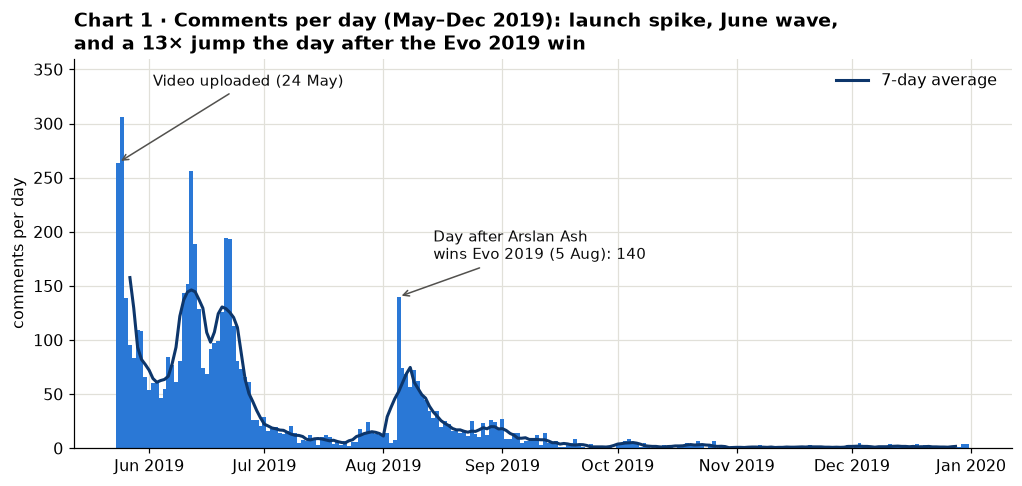

Average comments/day 20 Jul – 3 Aug 2019: 10.4  →  5 Aug 2019: 140  (13× jump)
Comments after 31 Dec 2019 (long tail, ~7 years): 1,261


In [16]:
# Chart 1: daily comments in the first 7 months, with the two key events
daily = df.set_index("published_at").resample("D").size()
window = daily["2019-05-24":"2019-12-31"]
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.bar(window.index, window.values, width=1.0, color=BLUE, linewidth=0)
ax.plot(window.index, window.rolling(7, center=True).mean(), color="#0d366b", lw=2, label="7-day average")
for date, label, y in [("2019-05-24", "Video uploaded (24 May)", 335), ("2019-08-05", "Day after Arslan Ash\nwins Evo 2019 (5 Aug): 140", 175)]:
    ax.annotate(label, xy=(pd.Timestamp(date, tz="UTC"), window[date]), xytext=(pd.Timestamp(date, tz="UTC") + pd.Timedelta(days=9), y),
                arrowprops=dict(arrowstyle="->", color="#52514e"), fontsize=9.5, color="#0b0b0b")
ax.set_title("Chart 1 · Comments per day (May–Dec 2019): launch spike, June wave,\nand a 13× jump the day after the Evo 2019 win")
ax.set_ylim(0, 360); ax.set_ylabel("comments per day"); ax.legend(frameon=False, loc="upper right")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.show()
late_july = daily["2019-07-20":"2019-08-03"].mean()
print(f"Average comments/day 20 Jul – 3 Aug 2019: {late_july:.1f}  →  5 Aug 2019: {daily['2019-08-05']}  ({daily['2019-08-05']/late_july:.0f}× jump)")
print(f"Comments after 31 Dec 2019 (long tail, ~7 years): {(df['published_at'] > '2019-12-31').sum():,}")

**Interpretation, Chart 1:** attention to this video is **event-driven, not steady**.
1. After the launch spike (24–25 May) and a second wave in mid-June, activity faded to about 10 comments a day by late July.
2. On **5 Aug 2019**, the day after Arslan Ash won **Evo 2019** in Las Vegas, comments **jumped 13× to 140**, and stayed high for about two weeks.
3. Many of these comments say so directly ("Who is re-watching this after he just won Evo 2019?" is the second most-liked comment).

The player's *later* success sent people back to an *older* video.

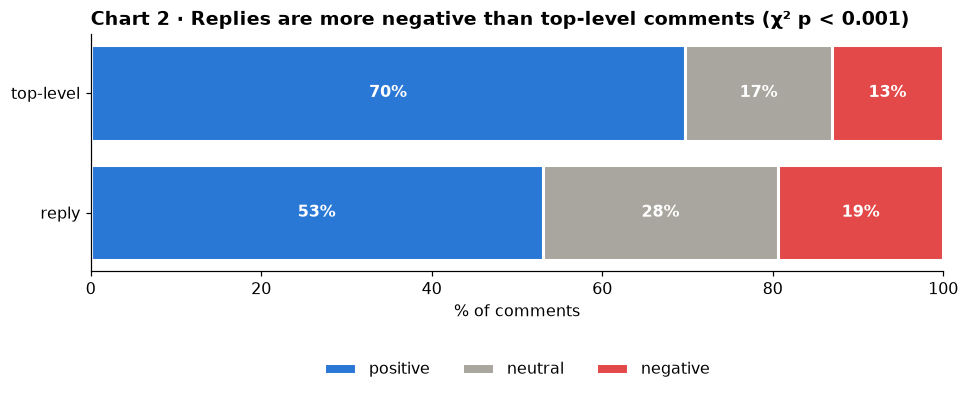

In [17]:
# Chart 2: mood of top-level comments vs replies (100% stacked bars)
pct = table.div(table.sum(axis=1), axis=0).loc[["top-level", "reply"]] * 100
fig, ax = plt.subplots(figsize=(10, 2.8))
left = np.zeros(len(pct))
for mood in ["positive", "neutral", "negative"]:
    ax.barh(pct.index, pct[mood], left=left, color=MOOD[mood], edgecolor="white", linewidth=2, label=mood)
    for i, v in enumerate(pct[mood]):
        ax.text(left[i] + v / 2, i, f"{v:.0f}%", ha="center", va="center", color="white", fontweight="bold")
    left += pct[mood].values
ax.set_xlim(0, 100); ax.invert_yaxis(); ax.grid(False); ax.set_xlabel("% of comments")
ax.set_title("Chart 2 · Replies are more negative than top-level comments (χ² p < 0.001)")
ax.legend(ncol=3, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.32))
plt.show()

**Interpretation, Chart 2:** top-level comments, the first thing a visitor sees, are overwhelmingly positive (70%). Reply threads are where disagreement lives: 19% negative vs 13%. For a brand, the **reply threads are the moderation risk**, while the main comment section is a strong public endorsement.

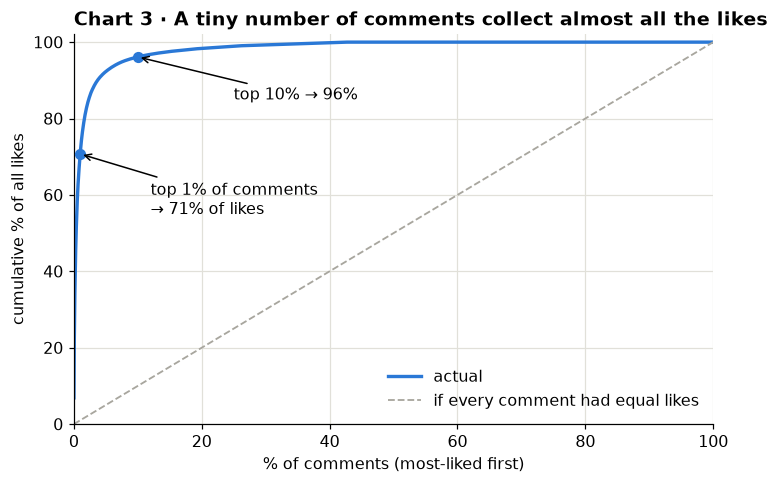

In [18]:
# Chart 3: Lorenz curve, how concentrated are likes?
shares = np.sort(df["like_count"].values)[::-1].cumsum() / df["like_count"].sum()
x = np.arange(1, len(shares) + 1) / len(shares) * 100
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.plot(x, shares * 100, color=BLUE, lw=2.2, label="actual")
ax.plot([0, 100], [0, 100], color=GREY, ls="--", lw=1.2, label="if every comment had equal likes")
ax.scatter([1, 10], [shares[int(len(shares)*.01)-1]*100, shares[int(len(shares)*.1)-1]*100], color=BLUE, zorder=3, s=40)
ax.annotate(f"top 1% of comments\n→ {shares[int(len(shares)*.01)-1]:.0%} of likes", (1, shares[int(len(shares)*.01)-1]*100), (12, 55), arrowprops=dict(arrowstyle="->"))
ax.annotate(f"top 10% → {shares[int(len(shares)*.1)-1]:.0%}", (10, shares[int(len(shares)*.1)-1]*100), (25, 85), arrowprops=dict(arrowstyle="->"))
ax.set_xlabel("% of comments (most-liked first)"); ax.set_ylabel("cumulative % of all likes")
ax.set_title("Chart 3 · A tiny number of comments collect almost all the likes")
ax.legend(frameon=False, loc="lower right"); ax.set_xlim(0, 100); ax.set_ylim(0, 102)
plt.show()

**Interpretation, Chart 3:** this is a **Lorenz curve**, a standard way to show inequality. If every comment had equal likes, the curve would follow the dashed line. Instead, the **top 1% of comments hold about 71% of all likes**, and 58% of comments have none. The few comments that rise to the top shape what millions of viewers read, so **what those top comments talk about matters most**. Chart 4 shows this.

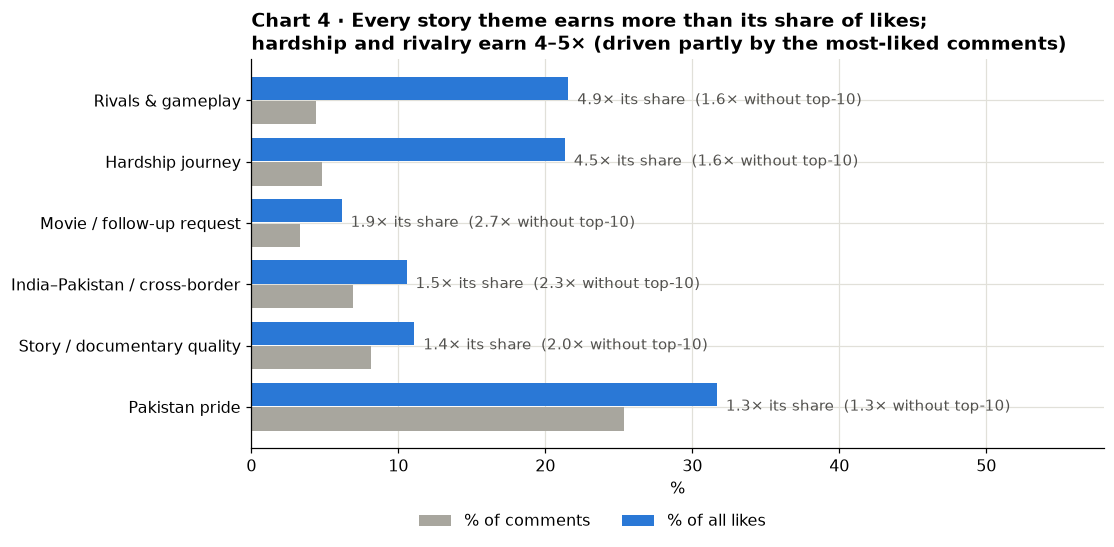

In [19]:
# Chart 4: share of comments vs share of likes, by theme
t = themes.sort_values("like multiplier")
yy = np.arange(len(t))
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.barh(yy - 0.2, t["% of comments"], height=0.38, color=GREY, label="% of comments")
ax.barh(yy + 0.2, t["% of all likes"], height=0.38, color=BLUE, label="% of all likes")
for i, (c, l, m, r) in enumerate(zip(t["% of comments"], t["% of all likes"], t["like multiplier"], t["multiplier excl. top-10"])):
    ax.text(max(c, l) + 0.6, i, f"{m:.1f}× its share  ({r:.1f}× without top-10)", va="center", fontsize=9.5, color="#52514e")
ax.set_yticks(yy, t.index); ax.set_xlabel("%"); ax.set_xlim(0, 58)
ax.set_title("Chart 4 · Every story theme earns more than its share of likes;\nhardship and rivalry earn 4–5× (driven partly by the most-liked comments)")
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.4, -0.13))
plt.show()

**Interpretation, Chart 4:** grey bars show how much people **talk** about a theme; blue bars show how much the audience **rewards** it with likes.
- **Pakistan pride** is the biggest conversation.
- The **underdog's struggle** (visa denials, no sleep) and the **rivalry** (beating Knee, perfect rounds) are what get liked most. Each is under 5% of comments but over 20% of likes, which includes the most-liked comments on the page.
- The figures in brackets remove those 10 viral comments. Every theme still beats its share, and movie/follow-up requests lead (2.7×).

The story, and the appetite for more of it, is what the audience values most.

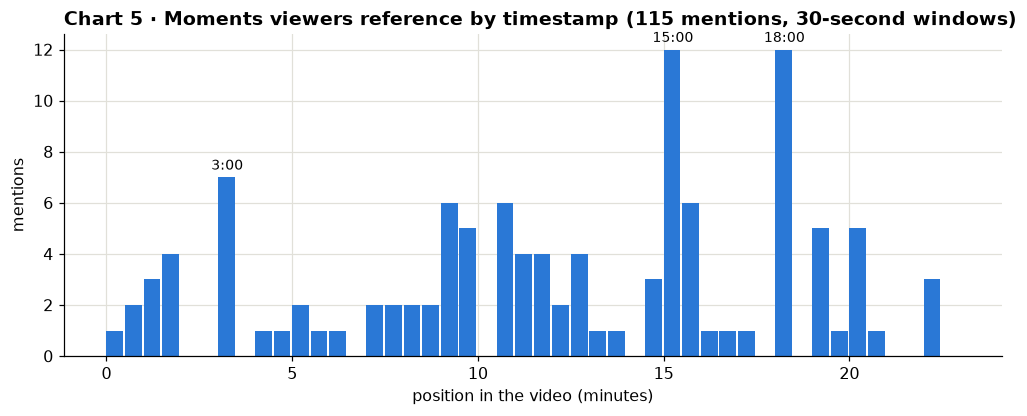

3:00 – 7 mentions · e.g. “3:04 "there's this random Pakistani dude killing all the Korean and Japanese guys......" 
”
15:00 – 12 mentions · e.g. “15:15 "You idiot. I'm sorry!" 🤣🤣”
18:00 – 12 mentions · e.g. “18:29 That selection taunt... i felt that in my soul”


In [20]:
# Chart 5: which moments of the video do viewers point to?
secs = df["timestamps_s"].explode().dropna().astype(int)
bins = np.arange(0, video["duration_seconds"] + 30, 30)
counts_t, _ = np.histogram(secs, bins=bins)
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(bins[:-1] / 60, counts_t, width=0.45, align="edge", color=BLUE)
for i in np.argsort(counts_t)[-3:]:
    ax.text(bins[i] / 60 + 0.25, counts_t[i] + 0.3, f"{int(bins[i]//60)}:{int(bins[i]%60):02d}", ha="center", fontsize=9)
ax.set_xlabel("position in the video (minutes)"); ax.set_ylabel("mentions")
ax.set_title(f"Chart 5 · Moments viewers reference by timestamp ({len(secs)} mentions, 30-second windows)")
plt.show()
for start in sorted(np.argsort(counts_t)[-3:]):
    s = bins[start]
    ex = df[df["timestamps_s"].map(lambda L: any(s <= x < s + 30 for x in L))].nlargest(1, "like_count")["text"].iloc[0]
    print(f"{int(s//60)}:{int(s%60):02d} – {counts_t[start]} mentions · e.g. “{ex[:90]}”")

**Interpretation, Chart 5:** viewers point to specific scenes, mostly the **tournament climax (15–19 min)**: the "You idiot. I'm sorry!" exchange, the handshake and the final taunt. These timestamps are a free, audience-chosen **edit list** for short ad cuts (see the recommendation in §10).

---
## 10. Evidence-based observations and marketing recommendation

### Observation 1: Engagement is event-driven, and later wins send people back to the old video
- 52% of all comments arrived in the first 30 days, and about 80% in the first 120.
- Then, on the day after Arslan Ash won **Evo 2019** (5 Aug 2019, 73 days after upload), comments **jumped 13×**, from about 10/day to 140/day, and stayed high for about two weeks (Chart 1).
- The second most-liked comment is literally about re-watching after that win.

### Observation 2: Likes go to the underdog story, not to positivity
- How positive a comment is has almost **no link** with its likes (Mann–Whitney p = 0.99; Spearman ρ = 0.07).
- What earns likes is **content**: comments about the **hardship journey** and the **rivalry** are under 5% of comments each, but earn **21–22% of all likes** (4.5–4.9× their share, Chart 4). These include the most-liked comments on the page.
- Beyond the viral few, ordinary viewers also reward the story: after removing the 10 most-liked comments, **movie / follow-up requests** earn 2.7× their share and **cross-border India–Pakistan** comments 2.3×.
- Likes are so concentrated (top 1% → 71% of likes, Chart 3) that the themes of the top comments become the public face of the comment section.

### Extra evidence: what the story does for Tekken as a brand
Before turning the observations into an advertising plan, we check four things in the comments: whether the story reaches **people who don't play**, whether it turns into **intent to play**, how much **national identity** matters, and how viewers see the **sponsors**.

In [21]:
SIGNALS = {
    "Says they don't play Tekken / aren't gamers":
        r"(?:don'?t|do not|never) (?:even )?(?:play|played|know|watch|follow) (?:tekken|fighting games|games|video games|esports|e-sports)"
        r"|not (?:even )?(?:a )?(?:gamer|tekken player|into (?:tekken|fighting games|gaming))",
    "Says they want to play / buy Tekken":
        r"(?:start(?:ed)?|want(?:ed)?|going|gonna|wanna|made me|makes me) (?:to )?(?:play|buy|download|get|try|pick up|learn) "
        r"(?:tekken|t7|t8|this game|the game|fighting games)|(?:buy|bought|install|download)(?:ed|ing)? tekken",
    "Inspired / emotional (inspiring, chills, cried)": r"inspir|motivat|goosebumps|chills|tears|cried|crying",
    "Mentions a nation (Pakistan, India, Korea, Japan…)": r"pakistan|pakistani|🇵🇰|india|korea|japan|turkey|türkiye|indonesia",
    "Mentions sponsors / brands": r"sponsor|red bull|redbull|brand",
    "Asks for a movie / film about him": r"movie|film|biopic|netflix",
}
avg_likes = df["like_count"].mean()
rank = df["like_count"].rank(ascending=False, method="min")
rows = []
for name, pattern in SIGNALS.items():
    m = df["text"].str.contains(pattern, case=False, regex=True)
    top = df[m].nlargest(1, "like_count")
    rows.append({"signal": name, "comments": int(m.sum()), "% of comments": m.mean() * 100,
                 "% of all likes": df.loc[m, "like_count"].sum() / total_likes * 100,
                 "avg likes vs overall": df.loc[m, "like_count"].mean() / avg_likes,
                 "best-liked example": f"#{int(rank[top.index[0]])} most-liked ({int(top['like_count'].iloc[0]):,} likes): "
                                       f"“{top['text'].iloc[0][:70]}…”"})
evidence = pd.DataFrame(rows).set_index("signal")
evidence.round(2)

,comments,% of comments,% of all likes,avg likes vs overall,best-liked example
signal,,,,,
Says they don't play Tekken / aren't gamers,47,0.67,0.69,1.03,#51 most-liked (451 likes): “Thank you very much for the Tekken-content. Even if i do not play Tekk…”
Says they want to play / buy Tekken,4,0.06,0.05,0.88,#211 most-liked (58 likes): “Tekken has never been this exciting before and I love how the tekken v…”
"Inspired / emotional (inspiring, chills, cried)",260,3.72,4.20,1.13,#27 most-liked (887 likes): “I'm from India but his story make me feel proud. You are inspiring. RE…”
"Mentions a nation (Pakistan, India, Korea, Japan…)",2256,32.27,41.59,1.29,"#2 most-liked (6,033 likes): “Basically, Pakistan is Wakanda in the Tekken World.\n\nUpdate: Arslan wo…”"
Mentions sponsors / brands,54,0.77,2.08,2.69,"#9 most-liked (2,226 likes): “Credit to his sponsors for actually doing work for him…”"
Asks for a movie / film about him,132,1.89,3.49,1.85,"#14 most-liked (1,659 likes): “They better make a goddamn movie about his life. This is some hollywoo…”"


**What this shows:**
- **The story reaches beyond players.** 47 comments say outright that they don't play Tekken but loved the video. Only **4 of 6,991 comments (0.06%)** say they want to play or buy it. The story wins **attention and goodwill**, but nothing in the video turns that into **trial**. That gap is what advertising can close.
- **Emotion is common.** 260 comments describe being inspired, getting chills or crying.
- **Identity is the biggest driver.** About a third of comments name a nation, and they collect about 41% of all likes.
- **Sponsors get credit when they are part of the story.** "Credit to his sponsors for actually doing work for him" is one of the 10 most-liked comments on the video (2,226 likes).
- **Viewers want more of the story.** 132 comments ask for a movie about him.

### Recommendation: "Champion's Road", player-story advertising for Tekken 8
**Who:** Bandai Namco (Tekken's publisher), co-funded with the sponsors of its star players and with tournament organisers such as Evo.

**What:** replace part of the usual gameplay-trailer advertising with a recurring **ad series in which each ad tells one real Tekken pro's journey**. Start with Arslan Ash: refused visas and no sleep in 2019 → Evo Japan and Evo 2019 champion → **eight Evo titles across Tekken 7 and Tekken 8 by mid-2026**. Other champions from different countries follow.

**How: build every ad on classical rhetoric (Aristotle's three appeals), each one backed by this data:**

| Appeal | Meaning | How the ad uses it | Evidence in the comments |
|---|---|---|---|
| **Pathos** (emotion) | Move the viewer | Open on the struggle: visa refusals, missed flights, playing on no sleep | Hardship comments earn **4.5×** their share of likes (Chart 4); 260 comments say they were inspired, got chills or cried |
| **Ethos** (credibility) | Trust the speaker | A *real*, verifiable champion telling his own story. Sponsors appear as the **people who made the journey possible**, not as logo slates | "Credit to his sponsors…" is a top-10 comment (2,226 likes) |
| **Logos** (proof) | Convince with facts | Put the results on screen: beating Knee, Evo titles, perfect rounds | Rivalry/gameplay comments earn **4.9×** their share of likes (Chart 4) |
| **Belonging** (identity) | "This is *our* hero" | Localise each ad for the player's home market and its neighbours (Urdu/Hindi for Pakistan and South Asia; Korean, Japanese, etc. for other players) | Pakistan pride is the largest theme (25%); cross-border India–Pakistan respect earns 2.3× its share of likes once viral comments are removed |

**Execution:**
1. **Formats:** 15–30-second pre-roll and Shorts cut from the moments viewers already point to (Chart 5: 15:00–19:00), plus a 3–5-minute mini-documentary per player. This answers the 132 "make a movie" requests.
2. **Timing:** release within 48 hours of a major tournament result, when attention spikes. After the Evo 2019 win, comments jumped 13× (Observation 1).
3. **Call to action:** the story attracts non-players but produces almost no intent to play (0.06%). So every ad ends with a direct invitation, such as a free Tekken 8 trial weekend or "watch the next Evo live", and the player's sponsor shown alongside.

**How to measure it:** run an **A/B test** of story-led ads against the standard gameplay trailer in the same markets.
- **Primary KPIs:** view-through rate, click-through to the Tekken 8 store page or free trial, and brand lift (awareness and purchase consideration, from a short survey).
- **Comment KPI:** the share of comments expressing intent to play. The baseline here is 0.06%.

**Risks:**
- The story must stay truthful, and the player must agree to how it's told.
- National-pride content also attracts arguments: replies are more negative (Chart 2), so the ads' comment sections need moderation.
- The evidence comes from one player and one video. Test it in one market before rolling it out.

---
## 11. Scaling experiment: pandas vs Apache Spark (PySpark)

**Question:** this video has 7k comments, which pandas handles in under a second. But a real marketing team would track a whole channel or a whole esports scene: thousands of videos and millions of comments, refreshed daily. **At what point does a distributed tool such as Spark become worthwhile?**

> 💡 **Concept: pandas vs Spark.**
> - **pandas** loads all the data into one computer's memory and mostly uses **one CPU core**.
> - **Apache Spark** splits the data into **partitions** and processes them **in parallel**: across all cores on a laptop (`local[*]`), or across many machines in a cluster. It is **lazy** (it plans the whole job before running it), it can spill to disk when the data is bigger than memory, and it recovers if a machine fails.
> - The price is **overhead**: starting the Java engine, planning, and scheduling tasks. That overhead dominates on small data.

**Method:**
- The cleaned comments are replicated ×1, ×10, ×25 and ×50 (6,991 → 349,550 rows) and saved as **Parquet** (a compressed, column-based file format).
- The same three-step job is timed in both tools, *including reading the file*:
  1. **Aggregate:** comments and average likes per month × comment type.
  2. **Word count:** tokenise all text, drop stopwords, find the top 20 words.
  3. **Sentiment:** score every comment with VADER, which is CPU-heavy. In Spark this runs as a Python UDF.
- Spark is warmed up first, so its one-off start-up cost isn't counted against the first size.
- Each step is timed once per size, to keep the notebook's run time short.

In [22]:
import os, shutil, tempfile, multiprocessing
from pyspark.sql import SparkSession, functions as F, types as T

print(f"Machine: {platform.system()} {platform.machine()} · {multiprocessing.cpu_count()} CPU cores · Python {platform.python_version()}")

def make_spark(cores):
    return (SparkSession.builder.master(f"local[{cores}]").appName("comment-scaling")
            .config("spark.ui.enabled", "false").config("spark.ui.showConsoleProgress", "false")
            .config("spark.driver.memory", "4g").config("spark.sql.shuffle.partitions", "8")
            .getOrCreate())

spark = make_spark("*")
spark.sparkContext.setLogLevel("ERROR")
print("Spark version:", spark.version, "| default parallelism:", spark.sparkContext.defaultParallelism)

STOP = set("the a to and of is i in he this it you that for was his but on so with be are not just have they "
           "from all at what an who him my me we your can how like".split())
BENCH_DIR = tempfile.mkdtemp(prefix="bench_")
base = df[["comment_id", "text", "like_count", "published_at", "is_reply"]].assign(
    published_at=df["published_at"].dt.strftime("%Y-%m-%dT%H:%M:%SZ"))

def pandas_job(path, step):
    d = pd.read_parquet(path)
    if step == "1 aggregate":
        return d.assign(month=d["published_at"].str[:7]).groupby(["month", "is_reply"]).agg(
            n=("comment_id", "size"), avg_likes=("like_count", "mean"))
    if step == "2 word count":
        w = d["text"].str.lower().str.findall(r"[a-z']+").explode()
        return w[~w.isin(STOP)].value_counts().head(20)
    if step == "3 sentiment":
        return d["text"].map(sentiment_score).mean()

@F.udf(T.DoubleType())
def sentiment_udf(text):
    return sentiment_score(text)

PARTITIONS = spark.sparkContext.defaultParallelism * 2   # units of parallel work (2 per core)

def spark_job(path, step, partitions=None):
    # A small file is read as ONE partition (= one task = one core), so we split it explicitly.
    d = spark.read.parquet(path).repartition(partitions or PARTITIONS)
    if step == "1 aggregate":
        return d.groupBy(F.substring("published_at", 1, 7).alias("month"), "is_reply").agg(
            F.count("*").alias("n"), F.avg("like_count").alias("avg_likes")).collect()
    if step == "2 word count":
        w = d.select(F.explode(F.split(F.lower("text"), "[^a-z']+")).alias("w"))
        return (w.where((F.length("w") > 0) & ~F.col("w").isin(list(STOP)))
                 .groupBy("w").count().orderBy(F.desc("count")).limit(20).collect())
    if step == "3 sentiment":
        return d.select(F.avg(sentiment_udf("text"))).collect()

def time_it(fn, *args, repeats=1):
    times = []
    for _ in range(repeats):
        t = time.perf_counter(); fn(*args); times.append(time.perf_counter() - t)
    return min(times)

base.to_parquet(f"{BENCH_DIR}/warm.parquet", index=False)
t0 = time.perf_counter(); spark_job(f"{BENCH_DIR}/warm.parquet", "1 aggregate")
print(f"Spark warm-up (JVM start + first job): {time.perf_counter() - t0:.1f} s, excluded from the results below")

Machine: Linux x86_64 · 2 CPU cores · Python 3.13.16


Spark version: 4.0.1 | default parallelism: 2


Spark warm-up (JVM start + first job): 5.1 s, excluded from the results below


In [23]:
results = []
for k in [1, 10, 25, 50]:
    big = pd.concat([base] * k, ignore_index=True)
    big["comment_id"] = big["comment_id"] + "_" + (big.index // len(base)).astype(str)
    path = f"{BENCH_DIR}/x{k}.parquet"
    big.to_parquet(path, index=False)
    mem_mb = big.memory_usage(deep=True).sum() / 1e6
    for step in ["1 aggregate", "2 word count", "3 sentiment"]:
        results.append({"rows": len(big), "step": step, "pandas_s": time_it(pandas_job, path, step),
                        "spark_s": time_it(spark_job, path, step), "pandas_RAM_MB": mem_mb})
    print(f"×{k:<3} {len(big):>8,} rows done")

bench = pd.DataFrame(results)
bench["faster"] = np.where(bench["pandas_s"] < bench["spark_s"], "pandas", "Spark")
bench["Spark / pandas time"] = (bench["spark_s"] / bench["pandas_s"]).round(2)
bench.round(2)

×1      6,991 rows done


×10    69,910 rows done


×25   174,775 rows done


×50   349,550 rows done


,rows,step,pandas_s,spark_s,pandas_RAM_MB,faster,Spark / pandas time
0,6991,1 aggregate,0.10,0.49,1.21,pandas,4.96
1,6991,2 word count,0.06,2.68,1.21,pandas,44.65
2,6991,3 sentiment,0.65,2.14,1.21,pandas,3.29
3,69910,1 aggregate,0.03,0.49,12.09,pandas,17.20
4,69910,2 word count,0.46,1.13,12.09,pandas,2.45
5,69910,3 sentiment,6.04,4.16,12.09,Spark,0.69
6,174775,1 aggregate,0.05,0.67,30.34,pandas,13.66
7,174775,2 word count,1.22,1.25,30.34,pandas,1.02
8,174775,3 sentiment,15.56,8.31,30.34,Spark,0.53
9,349550,1 aggregate,0.09,0.73,60.75,pandas,8.53


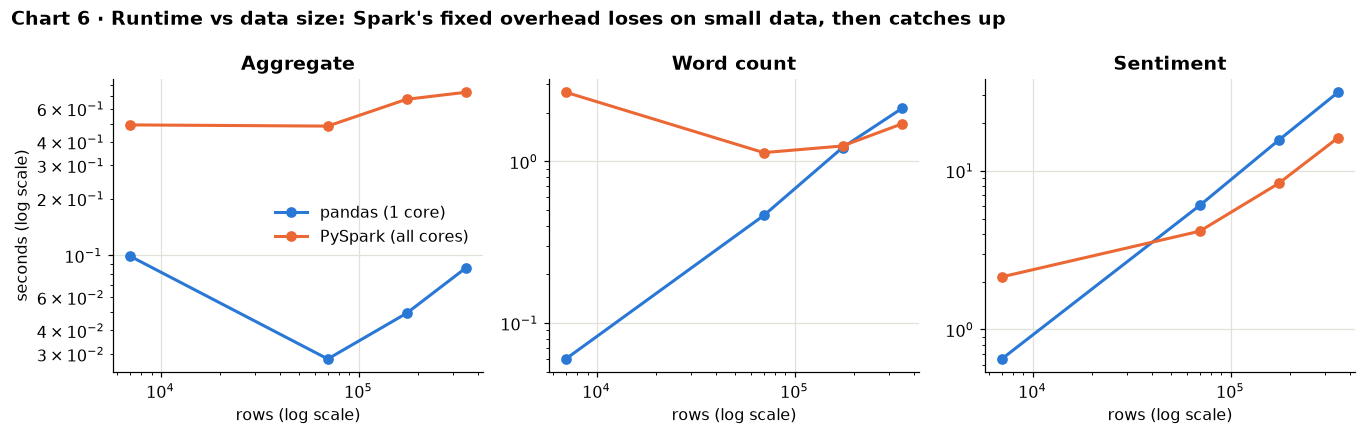

In [24]:
# Chart 6: runtime vs data size
fig, axes = plt.subplots(1, 3, figsize=(12.5, 4), sharex=True)
for ax, (step, g) in zip(axes, bench.groupby("step")):
    ax.plot(g["rows"], g["pandas_s"], "-o", color=BLUE, lw=2, ms=6, label="pandas (1 core)")
    ax.plot(g["rows"], g["spark_s"], "-o", color=ORANGE, lw=2, ms=6, label="PySpark (all cores)")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_title(step.split(" ", 1)[1].capitalize(), loc="center")
    ax.set_xlabel("rows (log scale)")
axes[0].set_ylabel("seconds (log scale)"); axes[0].legend(frameon=False)
fig.suptitle("Chart 6 · Runtime vs data size: Spark's fixed overhead loses on small data, then catches up", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

**Horizontal scaling test:** Spark's main advantage is that adding cores (or machines) speeds up the *same* job. Spark works on **partitions** (chunks of the data), and each core processes one partition at a time. The CPU-heavy sentiment step is run on the largest file split into 1, 2 and 4 partitions. With 1 partition only one core can work. This machine has 2 cores, so going beyond 2 partitions shouldn't help: a bigger speed-up would need more cores or more machines.

In [25]:
path_big = f"{BENCH_DIR}/x50.parquet"
scale = []
for parts in [1, 2, 4]:
    scale.append({"partitions (parallel tasks)": parts,
                  "sentiment on 349,550 rows (s)": time_it(lambda: spark_job(path_big, "3 sentiment", partitions=parts))})
scale = pd.DataFrame(scale)
scale["speed-up vs 1 partition"] = (scale.iloc[0, 1] / scale.iloc[:, 1]).round(2)
pandas_rate = len(base) * 50 / bench.query("rows == 349550 and step == '3 sentiment'")["pandas_s"].iloc[0]
display(scale)
print(f"pandas sentiment throughput: ~{pandas_rate:,.0f} comments/second on one core")
ram_per_m = bench["pandas_RAM_MB"].max() / bench["rows"].max() * 1e6 / 1e3
print(f"pandas RAM to hold just these 5 columns: ~{ram_per_m:.2f} GB per million comments "
      f"→ ~{ram_per_m * 50:.0f} GB for 50 million, before the 2–5× extra that processing copies usually need")
for n, label in [(1e6, "1 million comments"), (50e6, "50 million comments (e.g. a whole esports scene, re-scored daily)")]:
    print(f"  {label}: pandas ≈ {n / pandas_rate / 60:,.0f} min on one core  |  Spark on a 32-core cluster ≈ "
          f"{n / pandas_rate / 32 / 60 * 1.1:,.1f} min (assuming near-linear scaling + 10% overhead)")
spark.stop(); shutil.rmtree(BENCH_DIR, ignore_errors=True)

,partitions (parallel tasks),"sentiment on 349,550 rows (s)",speed-up vs 1 partition
0,1,33.895621,1.00
1,2,16.234591,2.09
2,4,16.669552,2.03


pandas sentiment throughput: ~11,181 comments/second on one core
pandas RAM to hold just these 5 columns: ~0.17 GB per million comments → ~9 GB for 50 million, before the 2–5× extra that processing copies usually need
  1 million comments: pandas ≈ 1 min on one core  |  Spark on a 32-core cluster ≈ 0.1 min (assuming near-linear scaling + 10% overhead)
  50 million comments (e.g. a whole esports scene, re-scored daily): pandas ≈ 75 min on one core  |  Spark on a 32-core cluster ≈ 2.6 min (assuming near-linear scaling + 10% overhead)


### Results of the scaling experiment
1. **Small data (this project, 7k rows): pandas wins every task.** Spark needs about 0.5–3 s per job, mostly overhead, for work pandas finishes in 0.1–0.7 s. Using Spark for one video would be over-engineering.
2. **Growing data:** pandas time and memory grow in proportion to the rows, because it uses one core and holds everything in RAM. Spark's fixed overhead gets spread out:
   - For **CPU-heavy sentiment scoring**, Spark is already faster at 70k rows and **about 2× faster at 350k rows** (≈16 s vs ≈31 s), even on this 2-core machine.
   - For **word counting**, Spark overtakes pandas at 350k rows.
   - For the **simple aggregation**, pandas stays faster throughout. It's too cheap for parallelism to matter at this size, so the right tool depends on the job, not only on the data size.
3. **Parallelism works:** splitting the sentiment job into 2 partitions on 2 cores gave about a **2× speed-up**. 4 partitions gave no further gain, because the machine only has 2 cores. On a cluster, the same code spreads across dozens of cores and machines **without being rewritten**, while pandas cannot use more than one machine.

*(Honest caveat: the benchmark ran on a small 2-core cloud machine, and the data was replicated rather than truly new. Absolute times will differ on other hardware, but the pattern — overhead first, parallel advantage later — is the general one.)*

---
## 12. Limitation, and why a scalable tool helps at larger scale

### Main limitation: lexicon-based sentiment misreads this story
VADER scores words, not meaning. This documentary is *about* hardship, so admiring comments that retell the struggle get scored as **negative**. For example, "He beat everyone on no sleep, no food, and jet lagged. I fear his true potential" (1,708 likes) scores −0.44. The examples below show it. So the **15% negative figure is an upper bound**, and real negativity is lower.

Other limitations:
- **One video, one snapshot:** results may not generalise to other videos or audiences.
- **Selection bias:** only about 3.4 per 1,000 viewers commented.
- **Keyword themes:** these miss paraphrases.
- **Non-English comments:** about 1% are Roman Urdu or Urdu, and another 1% are emoji-only. These are scored less reliably.

In [26]:
ex = df[(df["sentiment"] == "negative") & df["theme_Hardship journey"]].nlargest(5, "like_count")
ex[["text", "like_count", "sentiment_score"]]

,text,like_count,sentiment_score
962,"He beat everyone on no sleep, no food, and jet lagged. I fear his true potential",1708,-0.4427
5446,i almost cried when i knew he didn't eat or have a goodnight sleep before the tournament.\n\n\nyou never k...,351,-0.2526
4171,through all adversity and obstacles he went hungry and tired and STILL dominated all. Big up from Manches...,134,-0.8074
5543,They are afraid of giving Arslan visas because of the massive destruction he does in Tekken.,107,-0.3182
663,im glad the sponsors never gave up on him and kept getting him other flights until he was able to make it ...,95,-0.4310


### Why a scalable tool would help at a larger scale
1. **Better models need more computing power.** Fixing the limitation above means replacing VADER with a context-aware model (a fine-tuned transformer or an LLM). These are 100–1,000× slower per comment. Over millions of comments, that work has to be **spread across many cores or GPUs**, which is exactly what Spark (or Spark + GPU / batch inference) provides (§11, horizontal scaling).
2. **Generalising beyond one snapshot.** To fix the "one video" limitation, a team would analyse **every video on the channel and its competitors, refreshed regularly**. That is tens of millions of rows. That exceeds one laptop's memory (pandas needed about 0.17 GB of RAM per million comments just to hold five columns, so 50M comments need about 9 GB before processing, and typically 2–5× that while working), while Spark reads partitioned Parquet from cloud storage and spills to disk.
3. **Event-driven velocity.** Observation 1 shows comment volume spiking 13× around events. A system tracking many players in near-real time (e.g. **Spark Structured Streaming**) can absorb these bursts by adding machines, then scale back down.
4. **Same code, any size.** The PySpark code in §11 runs unchanged on a laptop or a 100-machine cluster. The pandas version would need rewriting.

---
## 13. Conclusion

- **Data:** 6,991 public comments, collected completely through the YouTube Data API, with no missing or duplicate records. One minor timestamp quirk was found and handled. The data was pseudonymised and used under the API terms.
- **What viewers feel:** about two-thirds positive (64.7%). Negativity is concentrated in reply-thread arguments, and is partly a measurement artefact of a hardship story.
- **What drives attention:** real-world **events** (Observation 1) and the **underdog/rivalry story** (Observation 2), not general positivity.
- **What to do:** use esports players' real stories as the rhetoric of Tekken advertising ("Champion's Road"): pathos from the hardship, ethos from a real champion and the sponsors who backed him, and logos from his titles. Localise the ads, time them to big wins, end each with a call to play, and test them against standard trailers.
- **Scale:** pandas is the right tool for one video. Spark becomes worthwhile, and soon necessary, once the same analysis covers a channel or an industry, or uses heavier AI models.

**Environment used to produce this notebook:**

In [27]:
import vaderSentiment, pyspark, scipy
print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | matplotlib {matplotlib.__version__} | "
      f"scipy {scipy.__version__} | vaderSentiment 3.3.2 | pyspark {pyspark.__version__}")

Python 3.13.16 | pandas 3.1.0 | numpy 2.5.4 | matplotlib 3.11.2 | scipy 1.18.1 | vaderSentiment 3.3.2 | pyspark 4.0.1


**References**
- Hutto, C. & Gilbert, E. (2014). *VADER: A Parsimonious Rule-based Model for Sentiment Analysis of Social Media Text.* ICWSM.
- Google. *YouTube Data API v3 reference* and *YouTube API Services Developer Policies*: https://developers.google.com/youtube
- Zaharia, M. et al. (2016). *Apache Spark: A Unified Engine for Big Data Processing.* Communications of the ACM 59(11).
- Evo 2019 result: ProPakistani, "Pakistan's Arslan Ash makes history by winning Tekken 7 tournament at EVO 2019" (5 Aug 2019).
- Eight Evo titles: ARY News, "Arslan Ash captures eighth EVO Tekken championship" (29 Jun 2026).
- Aristotle, *Rhetoric* (Book I): the three modes of persuasion, ethos, pathos and logos.